# Sentiment analysis three ways: neural networks and a sentiment lexicon

Three independent studies of human-written text, each testing a different NLP tool:

| Part | Data | Method |
|---|---|---|
| I | IMDb movie reviews (50,000) | Word embeddings + neural network, binary sentiment |
| II | COVID-19 tweets (41,157 + 3,798) | Text cleaning, lemmatisation, dense network vs LSTM, five sentiment classes |
| III | US airline tweets (14,640) | VADER sentiment lexicon, no training |

**Privacy:** user name columns are dropped and Twitter handles are masked as `@user` before any analysis.

**Tools:** `tensorflow`/`keras`, `nltk`, `scikit-learn`, `spacy`, `pandas`, `matplotlib`.

In [1]:
import html
import re
import warnings
from collections import Counter
from pathlib import Path

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

SEED = 42
tf.keras.utils.set_random_seed(SEED)
DATA = Path("../data")
FIG = Path("../figures")
FIG.mkdir(exist_ok=True)

INK, MUTED, GRID, ACCENT, SOFT, RED = "#1d1d1f", "#6e6e73", "#e5e5ea", "#2a78d6", "#b9c6d6", "#d64545"
plt.rcParams.update({
    "font.size": 10, "text.color": INK, "axes.edgecolor": GRID, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "savefig.dpi": 170, "savefig.bbox": "tight", "savefig.facecolor": "white",
})
save = lambda name: plt.gcf().savefig(FIG / f"{name}.png")

def plot_history(history, title, name):
    h = history.history
    fig, axes = plt.subplots(1, 2, figsize=(9, 3))
    for ax, key, label in [(axes[0], "accuracy", "Accuracy"), (axes[1], "loss", "Loss")]:
        ax.plot(h[key], color=ACCENT, label="Training")
        ax.plot(h[f"val_{key}"], color=RED, label="Validation")
        ax.set(xlabel="Epoch", title=label)
    axes[0].legend(frameon=False)
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    save(name)

def plot_confusion(y_true, y_pred, labels, title, name, figsize=(4.2, 3.6)):
    cm = confusion_matrix(y_true, y_pred, normalize="true")
    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, f"{cm[i, j]:.0%}", ha="center", va="center", fontsize=8.5, color="white" if cm[i, j] > 0.55 else INK)
    ax.set_xticks(range(len(labels)), labels, rotation=30, ha="right")
    ax.set_yticks(range(len(labels)), labels)
    ax.set(xlabel="Predicted", ylabel="Actual", title=title)
    ax.spines[:].set_visible(False)
    save(name)

## I. IMDb reviews: a neural network with word embeddings

**Goal:** a binary classifier that predicts whether a movie review is positive or negative. Keras ships the dataset already tokenised: 25,000 training and 25,000 test reviews, limited here to the 10,000 most frequent words (bag-of-words vocabulary).

In [2]:
from tensorflow.keras.datasets import imdb

NUM_WORDS, MAXLEN = 10_000, 256
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=NUM_WORDS)
word_index = imdb.get_word_index()
print(f"{len(x_train):,} training and {len(x_test):,} test reviews; {y_train.mean():.0%} positive")
print("Word index of 'good', 'well', 'bad':", word_index["good"], word_index["well"], word_index["bad"])

25,000 training and 25,000 test reviews; 50% positive
Word index of 'good', 'well', 'bad': 49 70 75


**Validity check: turning numbers back into text.** Keras shifts every word index by 3, because 0, 1 and 2 are reserved for padding, the start marker and unknown words. The decoder must apply the same shift, otherwise the decoded review is word salad.

In [3]:
index_to_word = {i + 3: w for w, i in word_index.items()}
index_to_word.update({0: "<pad>", 1: "<start>", 2: "<unk>"})

def decode(sequence):
    return " ".join(index_to_word.get(i, "?") for i in sequence if i > 1)

print(decode(x_train[0])[:400], "...")
print("Label:", ["negative", "positive"][y_train[0]])

this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <unk> is an amazing actor and now the same being director <unk> father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was jus ...
Label: positive


**Padding.** Reviews have different lengths, but the network needs equal-length inputs. Every review is cut or padded to 256 tokens with the reserved padding index 0, which carries no meaning.

In [4]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

print("Lengths before padding:", [len(x) for x in (x_train[0], x_train[1], x_test[0], x_test[1])])
x_train = pad_sequences(x_train, maxlen=MAXLEN, padding="post", value=0)
x_test = pad_sequences(x_test, maxlen=MAXLEN, padding="post", value=0)
print("Lengths after padding: ", [len(x) for x in (x_train[0], x_train[1], x_test[0], x_test[1])])

Lengths before padding: [218, 189, 68, 260]


Lengths after padding:  [256, 256, 256, 256]


**Model.** An embedding layer learns a 16-dimensional vector for each of the 10,000 words. Global average pooling turns a review into one 16-dimensional vector, a dense ReLU layer follows, and a sigmoid output gives the probability of a positive review. Optimiser: Adam; loss: binary cross-entropy; 20 % of the training set is held out for validation.

In [5]:
from tensorflow.keras import layers

imdb_model = tf.keras.Sequential([
    layers.Input(shape=(MAXLEN,)),
    layers.Embedding(NUM_WORDS, 16),
    layers.GlobalAveragePooling1D(),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])
imdb_model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
imdb_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 256, 16)        │       160,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 16)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 160,289 (626.13 KB)

 Trainable params: 160,289 (626.13 KB)

 Non-trainable params: 0 (0.00 B)

Final epoch: training accuracy 0.978, validation accuracy 0.863


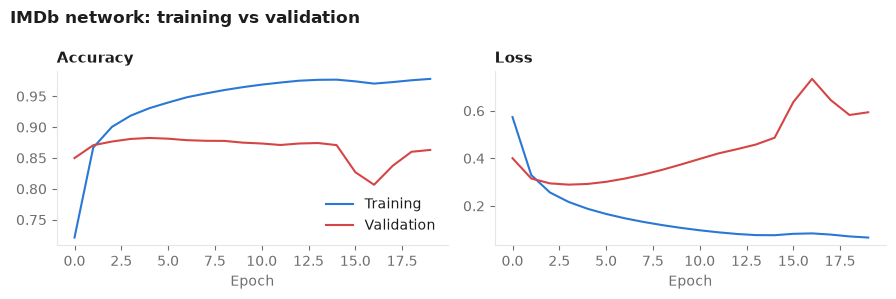

In [6]:
EPOCHS = 20
imdb_history = imdb_model.fit(x_train, y_train, validation_split=0.2, epochs=EPOCHS, batch_size=32, verbose=0)
h = imdb_history.history
print(f"Final epoch: training accuracy {h['accuracy'][-1]:.3f}, validation accuracy {h['val_accuracy'][-1]:.3f}")
plot_history(imdb_history, "IMDb network: training vs validation", "i_01_imdb_training")

Test accuracy: 0.8486


              precision    recall  f1-score   support

    negative      0.851     0.845     0.848     12500
    positive      0.846     0.852     0.849     12500

    accuracy                          0.849     25000
   macro avg      0.849     0.849     0.849     25000
weighted avg      0.849     0.849     0.849     25000



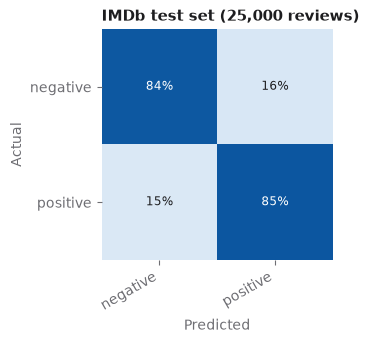

In [7]:
loss, acc = imdb_model.evaluate(x_test, y_test, verbose=0)
imdb_pred = (imdb_model.predict(x_test, verbose=0).ravel() > 0.5).astype(int)
print(f"Test accuracy: {acc:.4f}")
print(classification_report(y_test, imdb_pred, target_names=["negative", "positive"], digits=3))
plot_confusion(y_test, imdb_pred, ["negative", "positive"], "IMDb test set (25,000 reviews)", "i_02_imdb_confusion", figsize=(3.4, 3))

In [8]:
# One test review and the model's prediction
p = float(imdb_model.predict(x_test[:1], verbose=0)[0, 0])
print(decode(x_test[0])[:300], "...")
print(f"Predicted: {'positive' if p > 0.5 else 'negative'} (p = {p:.2f}); actual: {['negative', 'positive'][y_test[0]]}")

please give this one a miss br br <unk> <unk> and the rest of the cast rendered terrible performances the show is flat flat flat br br i don't know how michael madison could have allowed this one on his plate he almost seemed to know this wasn't going to work out and his performance was quite <unk>  ...
Predicted: positive (p = 0.76); actual: negative


**Result.** The small network (160,289 parameters) reaches about 85 % accuracy on the 25,000 unseen test reviews, balanced across both classes. Training accuracy keeps rising while validation accuracy flattens after a few epochs, the usual sign of overfitting; early stopping or dropout would be the next step. A neural network is a suitable tool for detecting sentiment patterns in a large text corpus.

## II. COVID-19 tweets: dense network vs LSTM

**Data:** the public [Coronavirus tweets NLP](https://www.kaggle.com/datasets/datatattle/covid-19-nlp-text-classification) dataset, labelled in five classes from *extremely negative* to *extremely positive*. Download `Corona_NLP_train.csv` and `Corona_NLP_test.csv` into `data/`.

**Privacy:** the user name columns are dropped at load time and every `@handle` is replaced with `@user`.

In [9]:
def load_tweets(path):
    df = pd.read_csv(path, encoding="latin1")
    df = df.drop(columns=["UserName", "ScreenName"])
    df["OriginalTweet"] = df["OriginalTweet"].map(lambda t: html.unescape(html.unescape(t)))  # &amp;amp; -> &
    # Repair broken Windows-1252 quotes ("LetÂ\x92s" -> "Let's")
    df["OriginalTweet"] = (df["OriginalTweet"].str.replace("Â", "", regex=False)
                           .str.translate({0x91: "'", 0x92: "'", 0x93: '"', 0x94: '"', 0x96: "-", 0x97: "-"}))
    df["OriginalTweet"] = df["OriginalTweet"].str.replace(r"@\w+", "@user", regex=True)
    return df

train_raw = load_tweets(DATA / "Corona_NLP_train.csv")
test_raw = load_tweets(DATA / "Corona_NLP_test.csv")
print("Train:", train_raw.shape, " Test:", test_raw.shape)
print("Missing values (train):", train_raw.isna().sum().to_dict())
print("Duplicate tweets (train):", train_raw.duplicated("OriginalTweet").sum())

Train: (41157, 4)  Test: (3798, 4)


Missing values (train): {'Location': 8590, 'TweetAt': 0, 'OriginalTweet': 0, 'Sentiment': 0}
Duplicate tweets (train): 16


Sentiment
Extremely Negative    0.133
Negative              0.241
Neutral               0.187
Positive              0.278
Extremely Positive    0.161
Name: proportion, dtype: float64

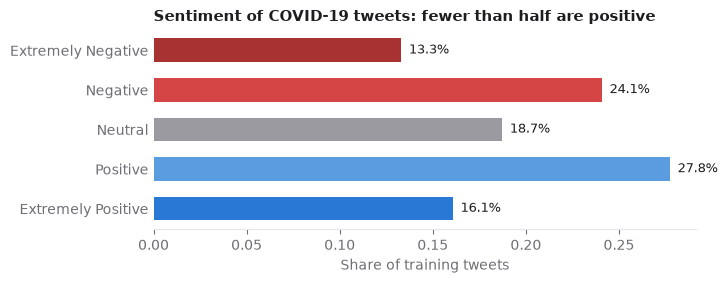

In [10]:
CLASSES = ["Extremely Negative", "Negative", "Neutral", "Positive", "Extremely Positive"]
COLORS = ["#a83232", RED, "#9a9aa0", "#5b9be0", ACCENT]
share = train_raw["Sentiment"].value_counts(normalize=True).reindex(CLASSES)
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.barh(CLASSES[::-1], share[::-1], color=COLORS[::-1], height=0.6)
for y, v in enumerate(share[::-1]):
    ax.text(v + 0.004, y, f"{v:.1%}", va="center", fontsize=9)
ax.set_xlabel("Share of training tweets")
ax.set_title("Sentiment of COVID-19 tweets: fewer than half are positive")
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
save("ii_01_sentiment_distribution")
share.round(3)

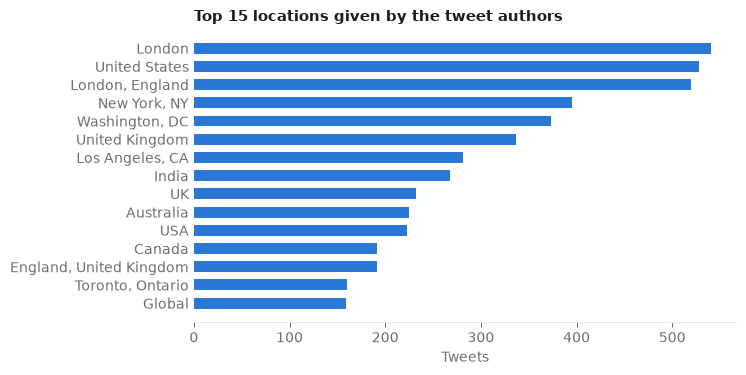

In [11]:
top_loc = train_raw["Location"].value_counts().head(15)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(top_loc.index[::-1], top_loc.values[::-1], color=ACCENT, height=0.6)
ax.set_xlabel("Tweets")
ax.set_title("Top 15 locations given by the tweet authors")
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
save("ii_02_top_locations")

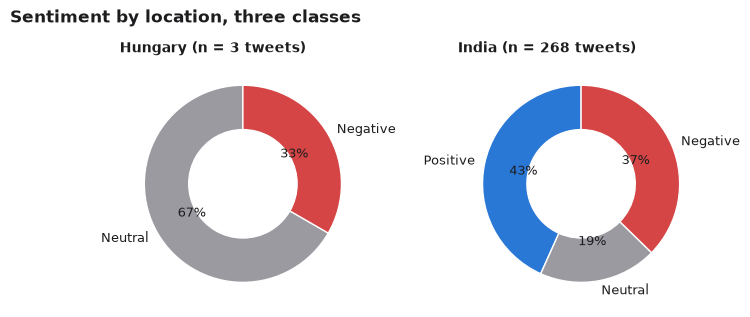

In [12]:
def three_way(s):
    return s.replace({"Extremely Positive": "Positive", "Extremely Negative": "Negative"})

fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
for ax, country in zip(axes, ["Hungary", "India"]):
    sub = three_way(train_raw.loc[train_raw["Location"] == country, "Sentiment"]).value_counts().reindex(["Positive", "Neutral", "Negative"]).fillna(0)
    sub = sub[sub > 0]
    ax.pie(sub, labels=sub.index, colors=[{"Positive": ACCENT, "Neutral": "#9a9aa0", "Negative": RED}[k] for k in sub.index],
           autopct="%1.0f%%", startangle=90, wedgeprops=dict(width=0.45, edgecolor="white"), textprops=dict(fontsize=9))
    ax.set_title(f"{country} (n = {int(sub.sum())} tweets)", fontsize=10)
fig.suptitle("Sentiment by location, three classes", x=0.01, y=1.04, ha="left", fontweight="bold")
save("ii_03_hungary_india")

India has enough tweets for a meaningful split (43 % positive, 37 % negative). Hungary, given as the location of only three tweets, is too small a sample to say anything about Hungarian sentiment; the comparison shows how uneven the geographic coverage of the dataset is.

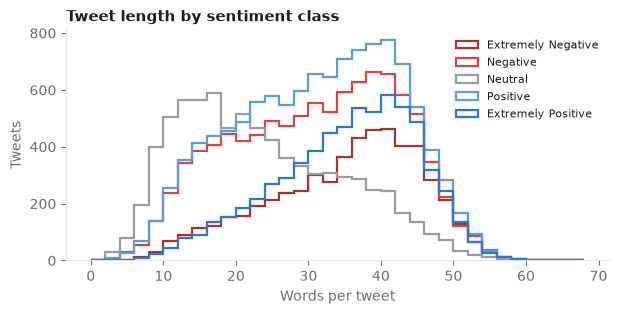

In [13]:
words = train_raw["OriginalTweet"].str.split().str.len()
fig, ax = plt.subplots(figsize=(7, 3))
for cls, color in zip(CLASSES, COLORS):
    ax.hist(words[train_raw["Sentiment"] == cls], bins=range(0, 70, 2), histtype="step", lw=1.6, color=color, label=cls)
ax.set(xlabel="Words per tweet", ylabel="Tweets", title="Tweet length by sentiment class")
ax.legend(frameon=False, fontsize=8)
save("ii_04_length_by_class")

**Most mentioned people and organisations.** Named entities (spaCy, English model) in the tweet text, with URLs, handles and hashtags removed first.

In [14]:
import spacy

nlp = spacy.load("en_core_web_sm", disable=["parser", "lemmatizer", "tagger", "attribute_ruler"])
texts = train_raw["OriginalTweet"].str.replace(r"https?://\S+|@user|#\w+", " ", regex=True)
ents = Counter(
    e.text.strip() for doc in nlp.pipe(texts, batch_size=500)
    for e in doc.ents if e.label_ in {"PERSON", "ORG"} and len(e.text.strip()) > 2
    and e.text.strip()[0].isupper() and not re.search(r"covid|corona|virus|pandemic|^don|^let", e.text, re.I)
)
pd.Series(dict(ents.most_common(12)), name="mentions")

Trump          265
NHS            252
Amazon         244
PPE            133
Supermarket    111
Walmart         93
Tesco           85
FDA             83
FTC             72
N95             66
Toilet          61
Learn           57
Name: mentions, dtype: int64

**Text cleaning.** Lower-casing, removing URLs, handles, hashtags, line breaks, punctuation and numbers, then English stop words, then WordNet lemmatisation.

*Fix:* in the original notebook the regular expressions ran without `regex=True`, which pandas 2 treats as plain text, so URLs and hashtags stayed in the text.

In [15]:
import nltk
from nltk.stem import WordNetLemmatizer
from wordcloud import STOPWORDS, WordCloud

nltk.download("wordnet", quiet=True)
lemmatizer = WordNetLemmatizer()
stop = set(STOPWORDS)

def clean(series):
    s = series.str.lower()
    s = s.str.replace(r"https?://\S+", " ", regex=True)    # URLs
    s = s.str.replace(r"@user|#\w+", " ", regex=True)      # masked handles, hashtags
    s = s.str.replace(r"[\r\n]+", " ", regex=True)         # line breaks
    s = s.str.replace("'", "", regex=False)                # don't -> dont
    s = s.str.replace(r"[^a-z\s]", " ", regex=True)        # punctuation and numbers
    return s.apply(lambda t: " ".join(lemmatizer.lemmatize(w) for w in t.split() if w not in stop and len(w) > 1))

train_raw = train_raw.drop_duplicates("OriginalTweet").dropna(subset=["OriginalTweet"])
train_raw["clean"] = clean(train_raw["OriginalTweet"])
test_raw["clean"] = clean(test_raw["OriginalTweet"])
example = train_raw.index[3]
print("Before:", train_raw.loc[example, "OriginalTweet"][:220].replace("\r", " ").replace("\n", " "))
print("After: ", train_raw.loc[example, "clean"])

Before: My food stock is not the only one which is empty...      PLEASE, don't panic, THERE WILL BE ENOUGH FOOD FOR EVERYONE if you do not take more than you need.    Stay calm, stay safe.      #COVID19france #COVID_19 #COVID19 
After:  food stock one empty please dont panic will enough food everyone take need stay calm stay safe


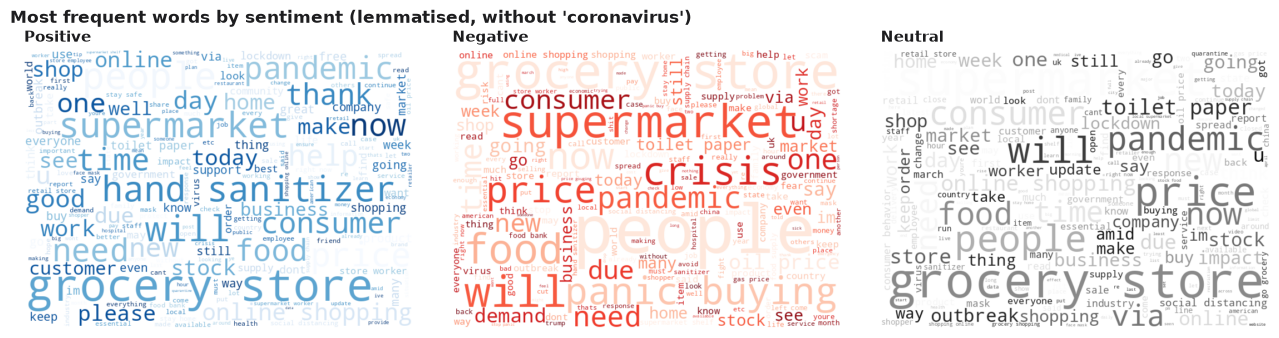

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
groups = {"Positive": ("Positive", "Extremely Positive"), "Negative": ("Negative", "Extremely Negative"), "Neutral": ("Neutral",)}
for ax, (name, members), cmap in zip(axes, groups.items(), ["Blues", "Reds", "Greys"]):
    text = " ".join(train_raw.loc[train_raw["Sentiment"].isin(members), "clean"])
    wc = WordCloud(width=700, height=500, background_color="white", colormap=cmap, random_state=SEED,
                   stopwords={"coronavirus", "covid", "covid19", "amp"}).generate(text)
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title(name)
    ax.axis("off")
fig.suptitle("Most frequent words by sentiment (lemmatised, without 'coronavirus')", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save("ii_05_wordclouds")

**Tokenisation, padding and labels.** The 10,000 most frequent words get an integer index, every tweet is padded to the longest cleaned tweet, and the five classes are one-hot encoded. The labelled training set is split 70/30 into training and validation; the separate test set is only used at the end.

*Fixes:* the original notebook measured tweet length in characters (305) instead of words, encoded the labels twice and never trained the baseline model.

In [17]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import to_categorical

VOCAB = 10_000
tokenizer = Tokenizer(num_words=VOCAB, oov_token="<oov>")
tokenizer.fit_on_texts(train_raw["clean"])
seq_len = int(train_raw["clean"].str.split().str.len().max())

def encode(texts):
    return pad_sequences(tokenizer.texts_to_sequences(texts), maxlen=seq_len, padding="pre")

label_id = {c: i for i, c in enumerate(CLASSES)}
X_all, y_all = encode(train_raw["clean"]), to_categorical(train_raw["Sentiment"].map(label_id), 5)
X_test_c, y_test_c = encode(test_raw["clean"]), to_categorical(test_raw["Sentiment"].map(label_id), 5)
X_tr, X_val, y_tr, y_val = train_test_split(X_all, y_all, test_size=0.3, random_state=SEED, stratify=y_all.argmax(1))
print(f"Vocabulary: {len(tokenizer.word_index):,} words (top {VOCAB:,} used); sequence length: {seq_len} words")
print("Train / validation / test:", X_tr.shape[0], X_val.shape[0], X_test_c.shape[0])

Vocabulary: 28,959 words (top 10,000 used); sequence length: 42 words
Train / validation / test: 28798 12343 3798


**Baseline: a dense neural network.** Embedding (128 dimensions), global average pooling, two small ReLU layers (16, 8) and a five-class softmax output. Early stopping keeps the weights of the best validation epoch.

Epochs run: 10; best validation accuracy: 0.692 (training 0.768)


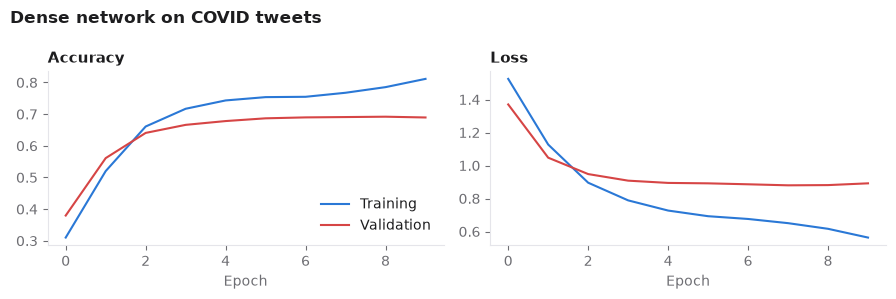

In [18]:
early = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
dnn = tf.keras.Sequential([
    layers.Input(shape=(seq_len,)),
    layers.Embedding(VOCAB, 128),
    layers.GlobalAveragePooling1D(),
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(5, activation="softmax"),
])
dnn.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
dnn_history = dnn.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=15, batch_size=64, callbacks=[early], verbose=0)
h = dnn_history.history
print(f"Epochs run: {len(h['loss'])}; best validation accuracy: {max(h['val_accuracy']):.3f} (training {h['accuracy'][int(np.argmin(h['val_loss']))]:.3f})")
plot_history(dnn_history, "Dense network on COVID tweets", "ii_06_dnn_training")

**LSTM.** The same embedding followed by an LSTM layer (512 units), which reads the words in order, and three dense layers (256, 128, 32).

Epochs run: 4; best validation accuracy: 0.732 (training 0.747)


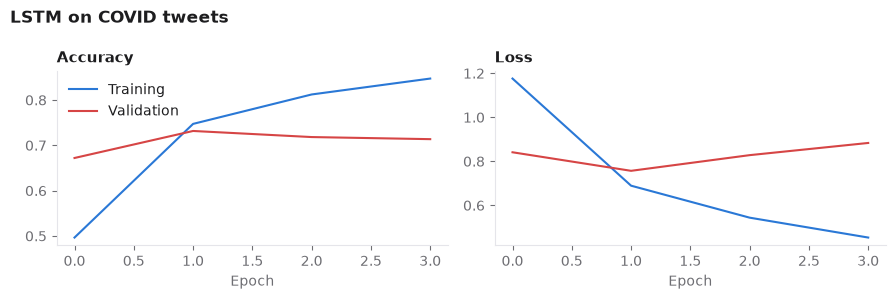

In [19]:
lstm = tf.keras.Sequential([
    layers.Input(shape=(seq_len,)),
    layers.Embedding(VOCAB, 128),
    layers.LSTM(512),
    layers.Dense(256, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(5, activation="softmax"),
])
lstm.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
lstm_history = lstm.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=10, batch_size=64, callbacks=[early], verbose=0)
h = lstm_history.history
print(f"Epochs run: {len(h['loss'])}; best validation accuracy: {max(h['val_accuracy']):.3f} (training {h['accuracy'][int(np.argmin(h['val_loss']))]:.3f})")
plot_history(lstm_history, "LSTM on COVID tweets", "ii_07_lstm_training")

In [20]:
rows = []
y_true = y_test_c.argmax(1)
preds = {}
for name, model in [("Dense network", dnn), ("LSTM", lstm)]:
    preds[name] = model.predict(X_test_c, verbose=0).argmax(1)
    three = lambda y: np.select([y <= 1, y == 2], [0, 1], 2)
    rows.append({"Model": name, "Parameters": model.count_params(),
                 "Test accuracy (5 classes)": accuracy_score(y_true, preds[name]),
                 "Test accuracy (3 classes)": accuracy_score(three(y_true), three(preds[name]))})
covid_results = pd.DataFrame(rows).set_index("Model").round(3)
covid_results

,Parameters,Test accuracy (5 classes),Test accuracy (3 classes)
Model,,,
Dense network,1282245,0.651,0.793
LSTM,2761285,0.685,0.821


                    precision    recall  f1-score   support

Extremely Negative      0.752     0.672     0.710       592
          Negative      0.611     0.677     0.643      1041
           Neutral      0.768     0.737     0.752       619
          Positive      0.618     0.650     0.634       947
Extremely Positive      0.810     0.711     0.757       599

          accuracy                          0.685      3798
         macro avg      0.712     0.690     0.699      3798
      weighted avg      0.692     0.685     0.687      3798



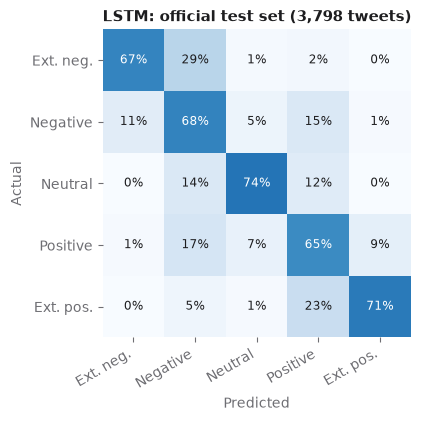

In [21]:
best = covid_results["Test accuracy (5 classes)"].idxmax()
short = ["Ext. neg.", "Negative", "Neutral", "Positive", "Ext. pos."]
plot_confusion(y_true, preds[best], short, f"{best}: official test set (3,798 tweets)", "ii_08_covid_confusion", figsize=(4.6, 4))
print(classification_report(y_true, preds[best], target_names=CLASSES, digits=3))

**Result.** Both networks learn the five-class task far above the 28 % majority baseline, and the LSTM is better on the unseen test set (68.5 % vs 65.1 %). Reading the words in order helps with negation and intensity. Most errors fall between neighbouring classes (for example *positive* vs *extremely positive*), so accuracy rises above 80 % when the classes are merged into three. Both models overfit after one or two epochs; early stopping keeps the best weights.

*Note:* the original working notebook reported the LSTM accuracy on its own training data and judged the dense network better; evaluated on the held-out test set, the LSTM comes out ahead.

## III. US airline tweets: the VADER sentiment lexicon

VADER (Valence Aware Dictionary and sEntiment Reasoner) scores each word from −4 to +4 and adjusts for intensifiers, negation, capitals, punctuation and emoticons. It needs no training. A tweet counts as positive if its compound score is at least 0.05, negative if at most −0.05, and neutral otherwise.

**Data:** the [Twitter US Airline Sentiment](https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment) dataset in its anonymised version from the [airline sentiment dashboard](https://github.com/rolandkeszi/USAir) repository (no user names, handles masked).

In [22]:
from nltk.sentiment import SentimentIntensityAnalyzer

nltk.download("vader_lexicon", quiet=True)
airline = pd.read_csv("https://raw.githubusercontent.com/rolandkeszi/USAir/main/data/Tweets.csv")
sia = SentimentIntensityAnalyzer()

def vader_label(text):
    c = sia.polarity_scores(text)["compound"]
    return "positive" if c >= 0.05 else "negative" if c <= -0.05 else "neutral"

airline["vader"] = airline["text"].apply(vader_label)
print(f"{len(airline):,} tweets; accuracy: {accuracy_score(airline['airline_sentiment'], airline['vader']):.4f}")
print(classification_report(airline["airline_sentiment"], airline["vader"], digits=2))

14,640 tweets; accuracy: 0.5429
              precision    recall  f1-score   support

    negative       0.90      0.50      0.64      9178
     neutral       0.38      0.43      0.41      3099
    positive       0.34      0.87      0.49      2363

    accuracy                           0.54     14640
   macro avg       0.54      0.60      0.51     14640
weighted avg       0.70      0.54      0.57     14640



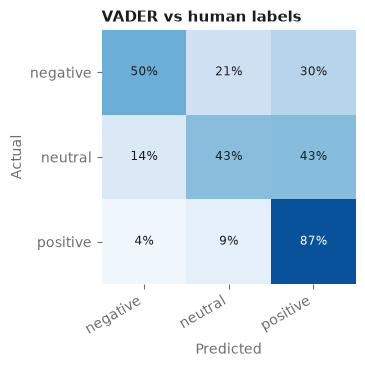

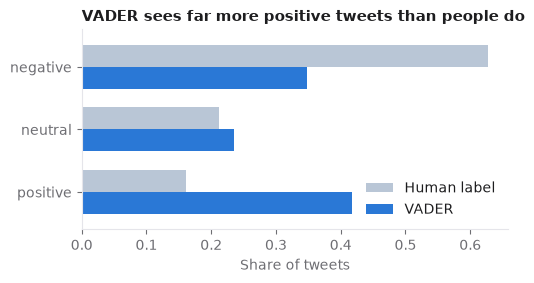

In [23]:
labels3 = ["negative", "neutral", "positive"]
plot_confusion(airline["airline_sentiment"], airline["vader"], labels3, "VADER vs human labels", "iii_01_vader_confusion", figsize=(3.8, 3.3))
fig, ax = plt.subplots(figsize=(5.5, 2.6))
comp = pd.DataFrame({"Human label": airline["airline_sentiment"].value_counts(normalize=True),
                     "VADER": airline["vader"].value_counts(normalize=True)}).reindex(labels3)
comp.plot.barh(ax=ax, color=[SOFT, ACCENT], width=0.7)
ax.invert_yaxis()
ax.set(xlabel="Share of tweets", title="VADER sees far more positive tweets than people do")
ax.legend(frameon=False)
save("iii_02_vader_distribution")

**Result.** VADER agrees with the human labels on only about 54 % of the tweets. It is precise on negative tweets (when it says negative, it is right 90 % of the time) but finds only half of them, and it labels many complaints as positive: polite words such as *thanks* or *please* carry positive valence even in a sarcastic or frustrated tweet. A lexicon is fast and transparent, but domain-specific text needs a trained model.

---
**References.** Maas et al. (2011), *Learning word vectors for sentiment analysis*, ACL. Hutto & Gilbert (2014), *VADER: a parsimonious rule-based model for sentiment analysis of social media text*, ICWSM.